# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Wahyu Adi Satrio
- NIM   : 241011402024
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 24

In [2]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Shape dataset: (40, 2)


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Shape X: (40, 1) | Shape y: (40,)


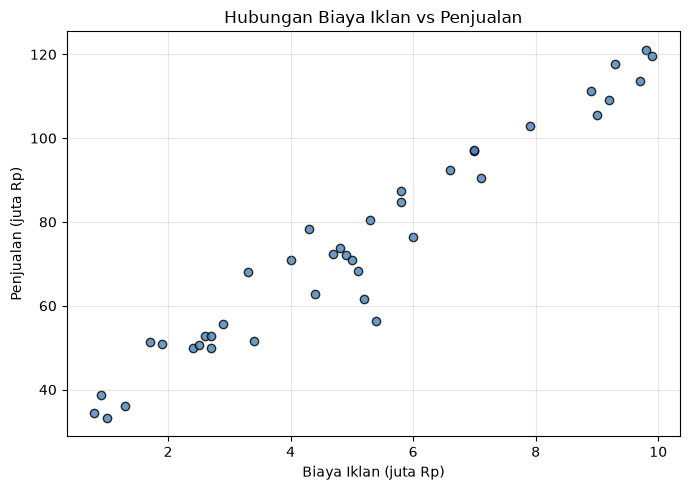

In [3]:
# Jawaban A1
df_ads = pd.read_csv("Ads_Data.csv")
print("Shape dataset:", df_ads.shape)
display(df_ads.head())

X_ads = df_ads[["BiayaIklan"]].values  
y_ads = df_ads["Penjualan"].values    
print("\nShape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_ads, y_ads, color="steelblue", edgecolor="black", alpha=0.8)
plt.title("Hubungan Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print("X_train:", X_train_a.shape)
print("X_test :", X_test_a.shape)
print("y_train:", y_train_a.shape)
print("y_test :", y_test_a.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.b = None  # Intercept
        self.m = None  # Koefisien

    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        # theta = (X^T X)^(-1) X^T y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.b = theta[0]
        self.m = theta[1:]
        return self

    def predict(self, X):
        return np.dot(X, self.m) + self.b


lr_model = LinearRegression()
lr_model.fit(X_train_a, y_train_a)

print(f"Intercept (b) = {lr_model.b:.4f}")
print(f"Koefisien (m) = {lr_model.m[0]:.4f}")
print(f"\nPersamaan Regresi Linear:")
print(f"y_hat = {lr_model.b:.4f} + {lr_model.m[0]:.4f} * X")

Intercept (b) = 28.1439
Koefisien (m) = 9.1356

Persamaan Regresi Linear:
y_hat = 28.1439 + 9.1356 * X


**Jawaban A3 (interpretasi):**

Persamaan regresi yang didapat adalah $\hat{y} = 28.1439 + 9.1356\,X$. Nilai $m = 9.1356$ berarti setiap kenaikan biaya iklan sebesar 1 juta Rp diikuti kenaikan penjualan rata-rata sekitar 9,14 juta Rp per bulan, dengan asumsi hubungan keduanya linear. Nilai $b = 28.14$ adalah penjualan yang diprediksi saat biaya iklan nol, tetapi data kita baru mulai dari biaya iklan 0,8 juta, jadi angka ini lebih tepat dibaca sebagai titik potong garis daripada angka penjualan nyata tanpa iklan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lr_model.predict(X_train_a)
y_pred_test = lr_model.predict(X_test_a)

hasil_a4 = pd.DataFrame({
    "MAE":  [mae(y_train_a, y_pred_train),  mae(y_test_a, y_pred_test)],
    "MSE":  [mse(y_train_a, y_pred_train),  mse(y_test_a, y_pred_test)],
    "RMSE": [rmse(y_train_a, y_pred_train), rmse(y_test_a, y_pred_test)],
    "R2":   [r2_score(y_train_a, y_pred_train), r2_score(y_test_a, y_pred_test)],
}, index=["Training", "Testing"])
hasil_a4.round(4)


,MAE,MSE,RMSE,R2
Training,4.8490,41.6282,6.4520,0.9326
Testing,3.0299,13.6585,3.6957,0.9800


**Jawaban A4 (analisis):**

RMSE pada data testing sebesar 3.70 (juta Rp) dan pada data training 6.45 (juta Rp). Artinya rata-rata prediksi model meleset sekitar 3,7 sampai 6,5 juta Rp dari penjualan sebenarnya, padahal penjualan berkisar sekitar 33 sampai 121 juta Rp. Nilai $R^2$ sebesar 0.9326 (training) dan 0.9800 (testing) berarti model menjelaskan sekitar 93% sampai 98% variasi penjualan hanya dari biaya iklan.

Menurut saya model ini sudah baik, karena kedua $R^2$ tinggi dan jaraknya kecil sehingga tidak ada tanda overfitting. Hasil testing yang justru sedikit lebih baik dari training kemungkinan besar kebetulan, sebab data testing hanya 8 titik. Karena itu angka testing jangan dianggap pasti lebih bagus dari training. Satu catatan lagi: sebaran residual di biaya iklan menengah (3 sampai 6 juta) lebih lebar daripada di ujung-ujungnya, jadi prediksi di rentang itu agak kurang pasti.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

C:\Users\Admin\AppData\Local\Temp\ipykernel_14784\3796139175.py:15: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(error ** 2))
c:\Users\Admin\AppData\Local\Programs\Python\Python315\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Admin\AppData\Local\Temp\ipykernel_14784\3796139175.py:17: RuntimeWarning: overflow encountered in matmul
  self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)
C:\Users\Admin\AppData\Local\Temp\ipykernel_14784\3796139175.py:17: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)


,Metode,learning_rate,Intercept,Koefisien
0,Normal Equation,-,28.143866,9.135571
1,Gradient Descent,0.001,24.640916,9.677853
2,Gradient Descent,0.02,28.143866,9.135571
3,Gradient Descent,0.1,NaN,NaN


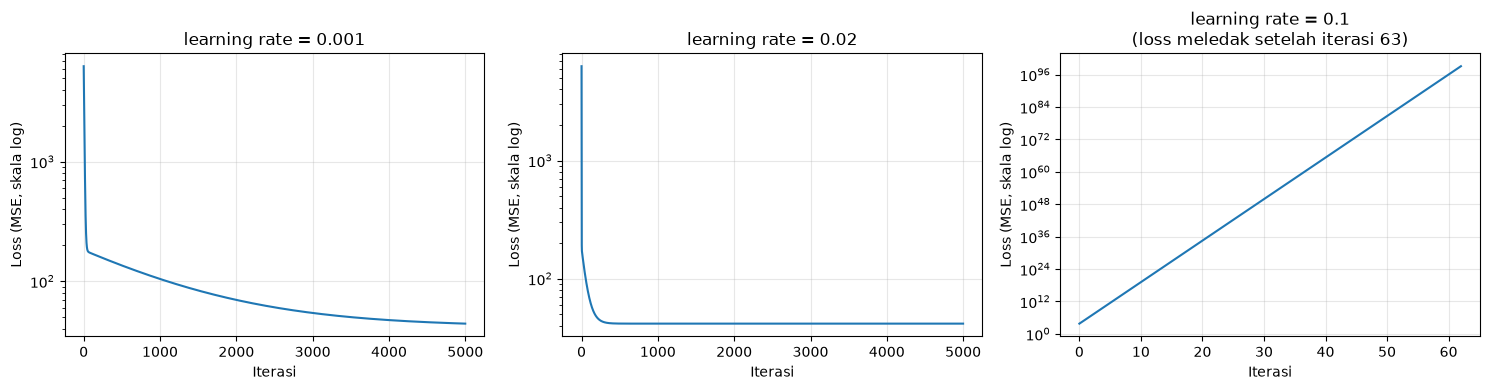

In [7]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history.append(np.mean(error ** 2))
            self.intercept_ -= self.learning_rate * (2 / n) * np.sum(error)
            self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
rows = [{"Metode": "Normal Equation", "learning_rate": "-",
         "Intercept": lr_model.b, "Koefisien": lr_model.m[0]}]

for lr in learning_rates:
    g = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train_a, y_train_a)
    gd_models[lr] = g
    rows.append({"Metode": "Gradient Descent", "learning_rate": lr,
                 "Intercept": g.intercept_, "Koefisien": g.coef_[0]})

display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    h = np.array(gd_models[lr].loss_history)
    ok = h < 1e100                     
    ax.plot(np.arange(len(h))[ok], h[ok])
    ax.set_yscale("log")
    judul = f"learning rate = {lr}"
    if not ok.all():
        judul += f"\n(loss meledak setelah iterasi {ok.sum()})"
    ax.set_title(judul)
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("Loss (MSE, skala log)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Hasil gradient descent pada 5000 iterasi:
- **learning rate 0.001.** Hasil akhirnya b = 24.64 dan m = 9.68, masih jauh dari normal equation (b = 28.14, m = 9.14), dan loss akhir 44.15 masih di atas loss minimum 41.63. Langkahnya terlalu kecil sehingga 5000 iterasi belum cukup untuk sampai ke titik minimum.
- **learning rate 0.02.** Loss turun cepat lalu mendatar, dan hasilnya sama dengan normal equation sampai 4 desimal (b = 28.1439, m = 9.1356, loss 41.63). Ini membuktikan kedua metode menyelesaikan masalah yang sama.
- **learning rate 0.1 (divergen).** Loss bukannya turun tetapi membesar terus sampai melebihi batas angka float, lalu menjadi `NaN`, sehingga intercept dan koefisien juga `NaN`. Peringatan `RuntimeWarning: overflow` muncul karena nilai yang dihitung sudah terlalu besar untuk disimpan. Itu tanda bahwa gradient descent gagal konvergen.

Penyebabnya adalah ukuran langkah. Jika learning rate terlalu besar, update melompati titik minimum ke sisi seberang dan jaraknya lebih jauh dari sebelumnya, sehingga error makin besar di setiap iterasi. Untuk data ini (nilai X sampai sekitar 10 dan belum di-scaling), batas learning rate yang masih stabil kira-kira 0.029. Itu sebabnya 0.02 aman sedangkan 0.1 meledak.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

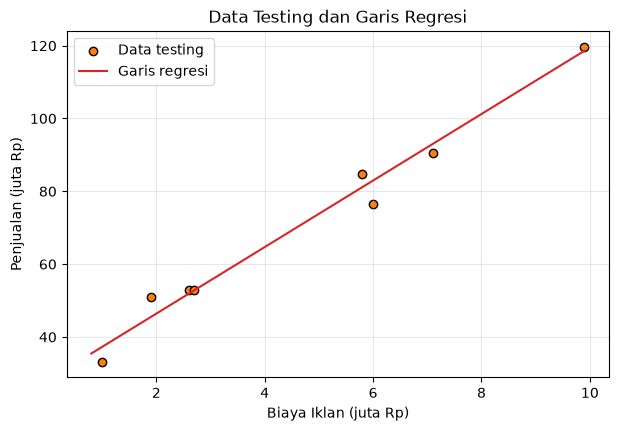

,BiayaIklan (juta),Prediksi Penjualan (juta)
0,4.5,69.25
1,7.0,92.09
2,12.0,137.77


Rentang BiayaIklan pada data: 0.8 - 9.9 juta


In [8]:
# Jawaban A6
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)

plt.figure(figsize=(7, 4.5))
plt.scatter(X_test_a, y_test_a, color="tab:orange", edgecolor="k", label="Data testing")
plt.plot(x_line, lr_model.predict(x_line), color="tab:red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lr_model.predict(biaya_baru)
display(pd.DataFrame({"BiayaIklan (juta)": biaya_baru.ravel(),
                      "Prediksi Penjualan (juta)": pred_baru.round(2)}))
print("Rentang BiayaIklan pada data: %.1f - %.1f juta" % (X_ads.min(), X_ads.max()))

**Jawaban A6 (analisis):**

Prediksi penjualan dari persamaan y = 28.1439 + 9.1356 × BiayaIklan, biaya iklan 4,5 juta menghasilkan 69.25 juta, 7 juta menghasilkan 92.09 juta, dan 12 juta menghasilkan 137.77 juta.

Prediksi untuk 12 juta adalah ekstrapolasi karena biaya iklan terbesar di data hanya 9,9 juta. Saya kurang bisa mempercayainya sepenuhnya. Model hanya belajar pola di rentang 0,8 sampai 9,9 juta. Di luar itu kita cuma mengasumsikan garisnya terus lurus, padahal di dunia nyata penambahan iklan biasanya memberi hasil yang makin kecil atau pasar mulai jenuh. Angka 137.77 juta tetap bisa dipakai sebagai perkiraan kasar, tetapi sebaiknya tidak dijadikan dasar keputusan tanpa data baru di rentang biaya iklan yang lebih tinggi. Sebaliknya, prediksi 4,5 juta dan 7 juta berada di dalam rentang data (interpolasi), jadi lebih bisa dipercaya.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah email         : 60
Jumlah Spam (1)      : 25
Jumlah Bukan Spam (0): 35


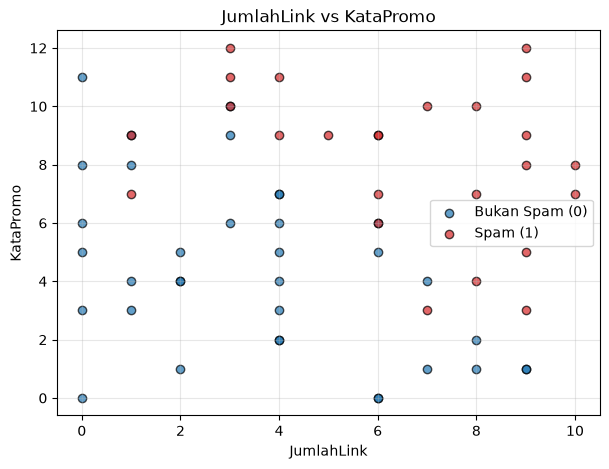

In [9]:
# Jawaban B1
df_email = pd.read_csv("Email_Data.csv")
display(df_email.head())
print("Jumlah email         :", len(df_email))
print("Jumlah Spam (1)      :", int((df_email["Spam"] == 1).sum()))
print("Jumlah Bukan Spam (0):", int((df_email["Spam"] == 0).sum()))

X_email = df_email[["JumlahLink", "KataPromo"]].values  
y_email = df_email["Spam"].values                       

plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], c="tab:blue", edgecolor="k", alpha=0.7, label="Bukan Spam (0)")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], c="tab:red", edgecolor="k", alpha=0.7, label="Spam (1)")
plt.title("JumlahLink vs KataPromo")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Pembagian data:
Data training : 45 baris
Data testing  : 15 baris
Total data    : 60 baris

Hasil pelatihan Logistic Regression:
Intercept (b)            : -11.4233
Koefisien m1 (JumlahLink): 1.0424
Koefisien m2 (KataPromo) : 0.8993

Persamaan model:
P(Spam) = sigmoid(-11.4233 + 1.0424 * JumlahLink + 0.8993 * KataPromo)


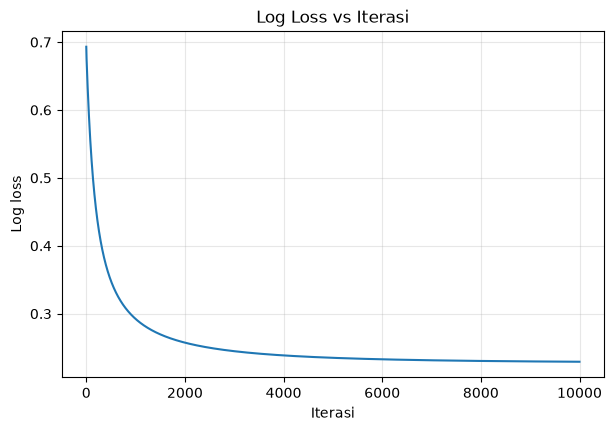


Log loss awal: 0.6931 | iterasi 1000: 0.2924 | akhir: 0.2292


In [10]:
# Jawaban B2
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE)

print("Pembagian data:")
print(f"Data training : {X_train_e.shape[0]} baris")
print(f"Data testing  : {X_test_e.shape[0]} baris")
print(f"Total data    : {X_train_e.shape[0] + X_test_e.shape[0]} baris")

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n = len(X)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history.append(loss)
            error = p - y
            self.intercept_ -= self.learning_rate * np.sum(error) / n
            self.coef_ -= self.learning_rate * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(X_train_e, y_train_e)
b_log = log_model.intercept_
m1, m2 = log_model.coef_

print("\nHasil pelatihan Logistic Regression:")
print(f"Intercept (b)            : {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1:.4f}")
print(f"Koefisien m2 (KataPromo) : {m2:.4f}")
print("\nPersamaan model:")
print(f"P(Spam) = sigmoid({b_log:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

plt.figure(figsize=(7, 4.5))
plt.plot(log_model.loss_history)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()
print(f"\nLog loss awal: {log_model.loss_history[0]:.4f} | iterasi 1000: {log_model.loss_history[999]:.4f} | akhir: {log_model.loss_history[-1]:.4f}")

**Jawaban B2 (analisis):**

Setelah dilatih, model yang saya dapat berbentuk P(Spam) = σ(-11.4233 + 1.0424 · JumlahLink + 0.8993 · KataPromo). Kedua koefisiennya positif, jadi semakin banyak link dan kata promosi dalam sebuah email, semakin besar kemungkinan email itu dianggap spam. Kalau dibandingkan, koefisien JumlahLink (1.04) sedikit lebih besar daripada KataPromo (0.90), artinya setiap tambahan satu link sedikit lebih kuat mendorong prediksi ke arah spam dibanding tambahan satu kata promosi.

Dari grafik log loss, terlihat bahwa loss dimulai dari 0.6931. Angka ini muncul karena semua bobot awalnya nol, sehingga model menebak peluang 0.5 untuk setiap email. Setelah itu loss turun cepat di awal, lalu perlahan melandai sampai sekitar 0.2292 di iterasi ke-10000. Pada 1000 iterasi terakhir, penurunannya hanya sekitar 0.0005, jadi bisa dibilang model sudah hampir konvergen dan tambahan iterasi tidak banyak mengubah hasilnya.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

y_pred_e = log_model.predict(X_test_e)
cm = confusion_matrix(y_test_e, y_pred_e)
print("Accuracy :", round(accuracy_score(y_test_e, y_pred_e), 4))
print("Precision:", round(precision_score(y_test_e, y_pred_e), 4))
print("Recall   :", round(recall_score(y_test_e, y_pred_e), 4))
print("F1-score :", round(f1_score(y_test_e, y_pred_e), 4))
display(pd.DataFrame(confusion_matrix(y_test_e, y_pred_e),
                     index=["Aktual Bukan Spam", "Aktual Spam"],
                     columns=["Prediksi Bukan Spam", "Prediksi Spam"]))
print(f"TN = {cm[0, 0]}, FP = {cm[0, 1]}, FN = {cm[1, 0]}, TP = {cm[1, 1]}")

Accuracy : 0.9333
Precision: 1.0
Recall   : 0.8571
F1-score : 0.9231


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,8,0
Aktual Spam,1,6


TN = 8, FP = 0, FN = 1, TP = 6


**Jawaban B3 (analisis):**

Pada data testing yang berisi 15 email, model mendapat accuracy 0.9333, precision 1.00, recall 0.8571, dan F1-score 0.9231. Kalau dilihat dari confusion matrix-nya, ada 8 email normal dan 6 email spam yang berhasil ditebak dengan benar. Tidak ada email normal yang salah dianggap spam (FP = 0), dan hanya ada satu spam yang lolos (FN = 1).

FP artinya email yang sebenarnya normal tetapi diprediksi spam, sedangkan FN artinya email spam yang justru lolos ke inbox. Menurut saya, FP lebih merugikan. Bayangkan email penting seperti info perkuliahan, tagihan, atau lowongan kerja masuk ke folder spam, bisa saja email itu tidak pernah terbaca dan akibatnya cukup serius. Sementara FN paling-paling hanya membuat satu email spam muncul di inbox, yang mengganggu tetapi mudah dihapus. Karena itu, pada filter spam saya lebih mengutamakan precision yang tinggi daripada recall.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

KataPromo = 12.7022 + (-1.1591) * JumlahLink


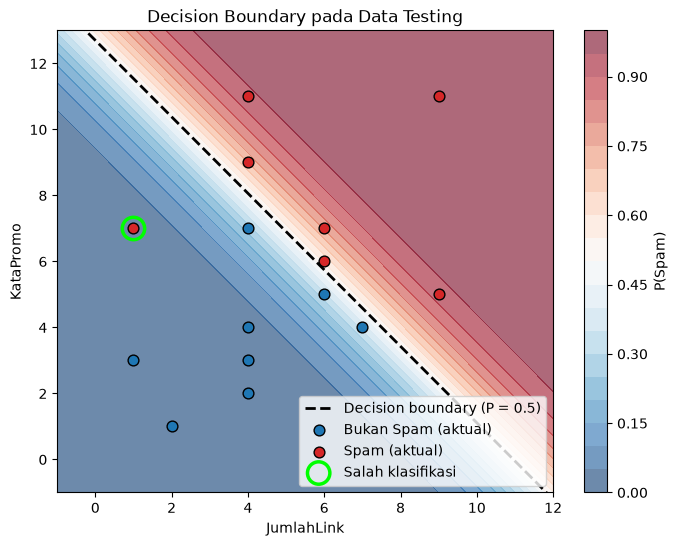

Salah klasifikasi: 1 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,1,7,1,0,0.017


In [12]:
# Jawaban B4
print(f"KataPromo = {-b_log/m2:.4f} + ({-m1/m2:.4f}) * JumlahLink")

x1_grid, x2_grid = np.meshgrid(np.linspace(-1, 12, 300), np.linspace(-1, 13, 300))
prob_grid = log_model.predict_proba(np.c_[x1_grid.ravel(), x2_grid.ravel()]).reshape(x1_grid.shape)

salah = y_pred_e != y_test_e
x1_line = np.linspace(-1, 12, 100)
x2_line = -(b_log + m1 * x1_line) / m2

plt.figure(figsize=(8, 6))
cf = plt.contourf(x1_grid, x2_grid, prob_grid, levels=20, cmap="RdBu_r", alpha=0.6)
plt.colorbar(cf, label="P(Spam)")
plt.plot(x1_line, x2_line, "k--", linewidth=2, label="Decision boundary (P = 0.5)")
plt.scatter(X_test_e[y_test_e == 0, 0], X_test_e[y_test_e == 0, 1], c="tab:blue", edgecolor="k", s=60, label="Bukan Spam (aktual)")
plt.scatter(X_test_e[y_test_e == 1, 0], X_test_e[y_test_e == 1, 1], c="tab:red", edgecolor="k", s=60, label="Spam (aktual)")
plt.scatter(X_test_e[salah, 0], X_test_e[salah, 1], s=260, facecolors="none", edgecolors="lime", linewidths=2.5, label="Salah klasifikasi")
plt.xlim(-1, 12); plt.ylim(-1, 13)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="lower right")
plt.show()

print("Salah klasifikasi:", int(salah.sum()), "dari", len(y_test_e))
display(pd.DataFrame({"JumlahLink": X_test_e[salah, 0], "KataPromo": X_test_e[salah, 1],
                      "Aktual": y_test_e[salah], "Prediksi": y_pred_e[salah],
                      "P(Spam)": log_model.predict_proba(X_test_e[salah]).round(3)}))

**Jawaban B4 (analisis):**

Decision boundary adalah garis tempat model berada tepat di batas keputusan, yaitu ketika peluang spam sama dengan 0.5. Itu terjadi saat b + m1 · JumlahLink + m2 · KataPromo = 0. Kalau persamaan ini diubah supaya KataPromo berada sendiri di satu sisi, hasilnya KataPromo = 12.7022 − 1.1591 · JumlahLink. Titik yang berada di atas garis diprediksi sebagai spam, sedangkan titik di bawahnya diprediksi bukan spam. Garisnya menurun karena kedua fitur bisa saling mengimbangi. Email dengan link yang sedikit tetap bisa dianggap spam kalau kata promosinya banyak, begitu juga sebaliknya.

Pada data testing, hanya 1 dari 15 email yang salah diklasifikasikan, yaitu email dengan JumlahLink = 1 dan KataPromo = 7. Email ini aslinya spam, tetapi model hanya memberi peluang spam 0.017, jadi diprediksi bukan spam. Kalau dilihat di grafik, posisinya jauh di bawah garis karena jumlah link-nya sangat sedikit, meskipun kata promosinya lumayan banyak. Model ini hanya bisa memisahkan data dengan garis lurus, sehingga kasus seperti ini memang sulit ditangkap.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = log_model.predict_proba(X_test_e)
rows = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    c = confusion_matrix(y_test_e, pred)
    rows.append({"Threshold": th, "TN": c[0, 0], "FP": c[0, 1], "FN": c[1, 0], "TP": c[1, 1],
                 "Accuracy": accuracy_score(y_test_e, pred),
                 "Precision": precision_score(y_test_e, pred),
                 "Recall": recall_score(y_test_e, pred),
                 "F1": f1_score(y_test_e, pred)})
hasil_b5 = pd.DataFrame(rows).set_index("Threshold")
hasil_b5.round(4)

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,6,2,1,6,0.8000,0.75,0.8571,0.8000
0.5,8,0,1,6,0.9333,1.00,0.8571,0.9231
0.7,8,0,3,4,0.8000,1.00,0.5714,0.7273


**Jawaban B5 (analisis):**

Threshold bisa dianggap sebagai seberapa yakin model harus sebelum menyebut sebuah email sebagai spam. Kalau threshold dinaikkan, model jadi lebih hati-hati: email normal jarang salah dituduh spam sehingga precision naik, tetapi lebih banyak spam yang lolos sehingga recall turun. Ini terlihat pada threshold 0.7, di mana FN naik dari 1 menjadi 3 dan recall turun ke 0.5714. Sebaliknya, kalau threshold diturunkan ke 0.3, model lebih mudah menyebut email sebagai spam. Dampaknya, email normal ikut terjaring (FP naik menjadi 2) dan precision turun ke 0.75.

Karena menurut saya FP lebih merugikan, saya memilih threshold 0.5. Pada data testing ini, threshold 0.5 dan 0.7 sama-sama tidak menghasilkan FP, tetapi 0.5 menjaga recall jauh lebih baik, yaitu 0.8571 dibanding 0.5714. Sementara threshold 0.3 malah menambah FP. Meski begitu, data testing yang dipakai hanya 15 email, jadi perbedaan antar threshold ini bisa saja berubah kalau datanya lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD = 0.5
email_baru = pd.DataFrame({"Email": ["E1", "E2", "E3", "E4"],
                           "JumlahLink": [1, 5, 9, 2],
                           "KataPromo": [2, 6, 10, 11]})
proba_baru = log_model.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = proba_baru.round(4)
email_baru["Prediksi"] = np.where(proba_baru >= THRESHOLD, "Spam", "Bukan Spam")
email_baru

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0002,Bukan Spam
1,E2,5,6,0.3068,Bukan Spam
2,E3,9,10,0.9990,Spam
3,E4,2,11,0.6351,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

Logistic Regression termasuk metode klasifikasi karena digunakan untuk menentukan suatu data masuk ke kelas tertentu, misalnya kelas 0 atau 1. Disebut regression karena menggunakan persamaan linear. Hasil perhitungan tersebut kemudian diubah menjadi probabilitas menggunakan fungsi sigmoid, dengan nilai antara 0 dan 1. Setelah itu, probabilitas digunakan untuk menentukan kelas berdasarkan batas tertentu, misalnya 0,5.

**Jawaban C2:**

Normal Equation dan Gradient Descent memiliki cara kerja yang berbeda. Normal Equation menghitung parameter model secara langsung, sedangkan Gradient Descent mencari parameter secara bertahap dengan memperbarui nilainya berdasarkan penurunan loss. Normal Equation tidak memerlukan learning rate, tetapi perhitungannya bisa menjadi berat jika jumlah fitur sangat banyak. Sementara itu, Gradient Descent lebih cocok untuk data berukuran besar dan model yang tidak memiliki solusi langsung, seperti Logistic Regression dan neural network. Pada percobaan A5, learning rate 0,02 menghasilkan parameter yang sama dengan Normal Equation.

**Jawaban C3:**

Model dievaluasi pada data testing karena tujuan kita adalah mengetahui seberapa baik model bekerja pada data baru yang belum pernah dilihat. Pada data training model sudah "melihat" jawabannya, sehingga nilainya cenderung terlalu bagus dan menyesatkan. Overfitting adalah kondisi saat model terlalu menghafal data training, termasuk noise-nya, sehingga skor di training sangat tinggi tetapi di data testing jauh lebih rendah. Selisih performa yang besar antara training dan testing adalah tanda utamanya.

**Jawaban C4:**

Linear Regression menghasilkan prediksi berupa angka kontinu, sehingga MSE digunakan untuk mengukur selisih antara hasil prediksi dan nilai sebenarnya. Sementara itu, Logistic Regression menghasilkan probabilitas untuk menentukan kelas, sehingga lebih cocok menggunakan Log Loss. Log Loss memberikan hukuman besar ketika model membuat prediksi yang sangat yakin tetapi ternyata salah. Jika MSE digunakan pada Logistic Regression, proses pelatihan bisa menjadi lebih sulit karena gradiennya dapat mengecil ketika fungsi sigmoid berada pada kondisi jenuh. Oleh karena itu, Log Loss lebih sesuai untuk melatih model klasifikasi.

**Jawaban C5:**

Hasil yang diperoleh bisa berbeda karena setiap mahasiswa menggunakan nilai random_state yang berbeda berdasarkan dua digit terakhir NIM. Akibatnya, pembagian data training dan testing juga bisa berbeda sehingga parameter model dan hasil evaluasinya tidak selalu sama. Perbedaan ini lebih terlihat jika jumlah data yang digunakan sedikit, seperti 40 atau 60 baris. Selain itu, perbedaan cara implementasi, seperti inisialisasi parameter dan jumlah iterasi, juga bisa memengaruhi hasil akhir.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

sk_lin = SkLinearRegression().fit(X_train_a, y_train_a)

print("Linear Regression")
print(f"Implementasi sendiri: b = {lr_model.b:.6f}, m = {lr_model.m[0]:.6f}, "
      f"R2 test = {r2_score(y_test_a, lr_model.predict(X_test_a)):.6f}")
print(f"scikit-learn        : b = {sk_lin.intercept_:.6f}, m = {sk_lin.coef_[0]:.6f}, "
      f"R2 test = {r2_score(y_test_a, sk_lin.predict(X_test_a)):.6f}")

sk_log      = SkLogisticRegression().fit(X_train_e, y_train_e)
sk_log_nopen = SkLogisticRegression(C=1e10, max_iter=10000).fit(X_train_e, y_train_e)

def tabel(nama, b, m, pred):

    return {
        "Model": nama,
        "b": b,
        "m1 (JumlahLink)": m[0],
        "m2 (KataPromo)": m[1],
        "Accuracy":  accuracy_score(y_test_e, pred),
        "Precision": precision_score(y_test_e, pred),
        "Recall":    recall_score(y_test_e, pred),
        "F1":        f1_score(y_test_e, pred),
    }

tabel_bonus = pd.DataFrame([
    tabel("Implementasi sendiri (tanpa regularisasi)",
            log_model.intercept_, log_model.coef_,
            log_model.predict(X_test_e)),
    tabel("sklearn default (L2, C=1.0)",
            sk_log.intercept_[0], sk_log.coef_[0],
            sk_log.predict(X_test_e)),
    tabel("sklearn tanpa regularisasi (C=1e10)",
            sk_log_nopen.intercept_[0], sk_log_nopen.coef_[0],
            sk_log_nopen.predict(X_test_e)),
])

tabel_bonus.round(4)

Linear Regression
Implementasi sendiri: b = 28.143866, m = 9.135571, R2 test = 0.979957
scikit-learn        : b = 28.143866, m = 9.135571, R2 test = 0.979957


,Model,b,m1 (JumlahLink),m2 (KataPromo),Accuracy,Precision,Recall,F1
0,Implementasi sendiri (tanpa regularisasi),-11.4233,1.0424,0.8993,0.9333,1.0,0.8571,0.9231
1,"sklearn default (L2, C=1.0)",-10.6331,0.9605,0.8379,0.9333,1.0,0.8571,0.9231
2,sklearn tanpa regularisasi (C=1e10),-12.8988,1.1842,1.0113,0.9333,1.0,0.8571,0.9231


**Jawaban Bonus (analisis):**

Linear Regression. Hasil scikit-learn sama persis dengan implementasi saya (b = 28.143866, m = 9.135571, R2 testing = 0.979957). Ini masuk akal karena keduanya menyelesaikan masalah least squares yang sama dengan solusi eksak, jadi tidak ada alasan hasilnya berbeda.

Logistic Regression. Koefisiennya berbeda, walaupun accuracy, precision, recall, dan F1 pada data testing sama (accuracy 0.9333, F1 0.9231). Model saya menghasilkan b = -11.4233, m1 = 1.0424, dan m2 = 0.8993. Sementara scikit-learn dengan pengaturan default (L2, C = 1.0) menghasilkan b = -10.6331, m1 = 0.9605, dan m2 = 0.8379. Ketika regularisasi hampir dimatikan (C = 1e10), koefisiennya justru jadi b = -12.8988, m1 = 1.1842, dan m2 = 1.0113.

Penyebab utamanya adalah regularisasi. Secara default, LogisticRegression di scikit-learn memakai penalti L2 dengan C = 1.0, yang menahan koefisien agar tidak terlalu besar. Itu sebabnya koefisiennya lebih kecil daripada milik saya yang tanpa regularisasi. Ketika regularisasi hampir dimatikan, koefisien scikit-learn justru jadi lebih besar daripada milik saya. Hal ini terjadi karena data hampir terpisah sempurna, sehingga loss terus turun kalau koefisien dibesarkan. Gradient descent saya berhenti di iterasi ke-10000 sebelum benar-benar konvergen, sedangkan solver scikit-learn berjalan sampai konvergen. Meskipun koefisiennya berbeda, garis pemisahnya mirip, sehingga prediksi kelas pada data testing tetap sama.